# Learning 2d $q$-state Potts Model with Cartegorical RBM

Kai Zhang, The Univeristy of Texas at Tyler, 2026

In [1]:
import os
from os import path
import sys

import matplotlib.pyplot as plt
import numpy as np

!which python
!python --version
print('numpy version:', np.__version__)

/home/tylerdell2/miniconda3/envs/.rbm_potts/bin/python
Python 3.11.18
numpy version: 2.4.6


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, random_split


# Check PyTorch GPU availability and set device

print("PyTorch version:", torch.__version__)
print('CUDA build:', torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("CUDA device count:", torch.cuda.device_count())
print('Capability:', torch.cuda.get_device_capability(0))


if torch.cuda.is_available():
    print("GPU device name:", torch.cuda.get_device_name(0))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.15.0+cu132
CUDA build: 13.2
CUDA available: True
CUDA device count: 1
Capability: (8, 9)
GPU device name: NVIDIA GeForce RTX 4090


In [16]:
q = 2
T = 1.550
L = 32
path = './2dPotts_L32/'
filename = os.path.join(path, "potts_configs_q2L32T{:.3f}.npy".format(T))
configs = np.load(filename)
print('analyze configuration file:', filename)
print(configs.shape)

analyze configuration file: ./2dPotts_L32/potts_configs_q2L32T1.550.npy
(20000, 1024)


In [4]:
# if you want to use self-defined colors
import matplotlib.colors as mcolors
# Define discrete colors
colors = ['red', 'blue'] # ['red', 'green', 'blue', 'orange']  # one color per spin
cmap = mcolors.ListedColormap(colors)
# Normalization: map integer values to colors
bounds = np.arange(q+1) - 0.5  # centers integers in color bins
norm = mcolors.BoundaryNorm(bounds, cmap.N)

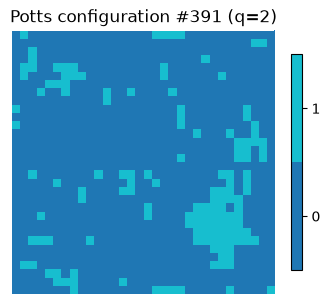

In [12]:
index = np.random.randint(configs.shape[0])
config = configs[index]

plt.figure(figsize=(4, 4))
plt.imshow(config.reshape(L,L), cmap="tab10", vmin=0, vmax=q-1)
#plt.imshow(config.reshape(L, L), cmap=cmap, norm=norm)

plt.title(f"Potts configuration #{index} (q={q})")
# plt.colorbar(label="Spin state")
plt.colorbar(ticks=np.arange(q),boundaries=bounds, spacing='uniform', shrink=0.7, fraction=0.1, pad=0.05)  # only integer ticks
plt.axis("off")
plt.show()

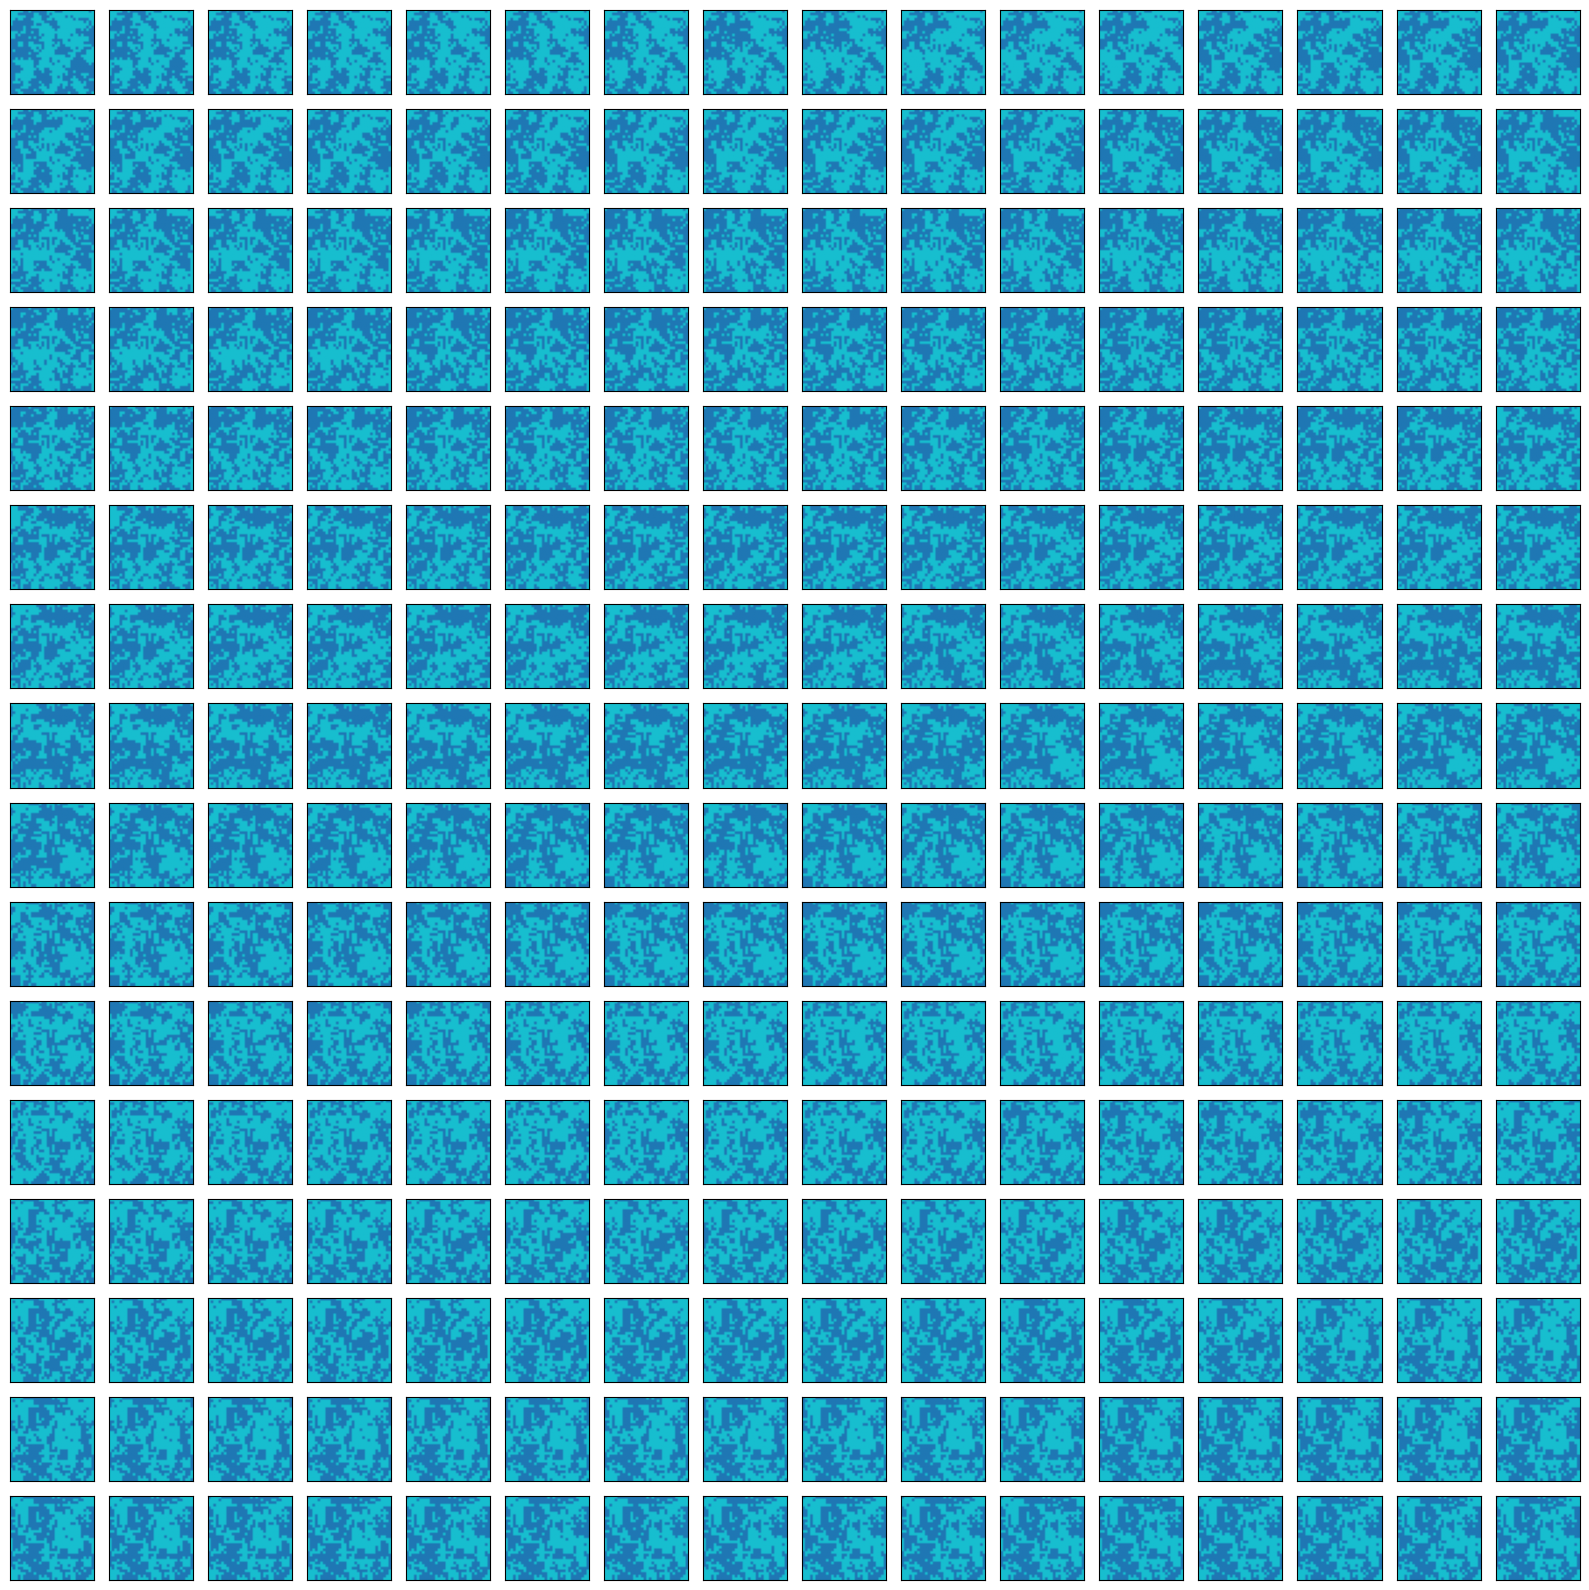

In [17]:
fig = plt.figure(figsize=(16, 16)) 
for i in range(256):  # 16 × 16 grid
    ax = fig.add_subplot(16, 16, i + 1)
    ax.imshow(configs[i].reshape(L, L), cmap='tab10')
    #ax.imshow(configs[i].reshape(L, L), cmap=cmap)
    # ax.axis('off')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

In [14]:
class OneHotTransform:
    def __init__(self, q):
        self.q = q

    def __call__(self, x):
        # x is a 1D tensor of integers: shape (L*L,)
        # Output will be (L*L, q) or with transpose (q, L*L)
        return torch.nn.functional.one_hot(x.long(), num_classes=self.q).float()  #.transpose(0, 1)
        
class PottsDataset(Dataset):
    def __init__(self, npy_path='./', q=4, transform=None):
        self.data = np.load(npy_path)  # numpy array (n_samples, L*L)
        self.data = torch.from_numpy(self.data).long()  # convert to tensor (int64)

        filename = os.path.basename(npy_path)
        T = float(filename.split("T")[1].split(".npy")[0])
        self.T_label = torch.tensor(T).float()  # regression label

        Tc = 1.0 / np.log(1.0 + np.sqrt(q))
        self.phase_label = torch.tensor(0 if T < Tc else 1).long()  # Phase classification label

        self.q = q
        self.transform = transform

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        x = self.data[idx]  # shape (L*L,)
        if self.transform:
            x = self.transform(x)
        return x, self.T_label  #, self.phase_label

In [16]:
q = 2  # example Potts model q
Tc = 1.0 / np.log(1.0 + np.sqrt(q))
print('q =', q, 'and Tc =', Tc)

transform = transforms.Compose([
    OneHotTransform(q),
    transforms.Lambda(lambda x: x.view(-1)),  # Flatten  
])

dataset = PottsDataset(npy_path=filename, q=q, transform=transform)

#dataset_size = len(dataset)
#train_size = int(0.8 * dataset_size)
#test_size  = dataset_size - train_size
#train_dataset, test_dataset = random_split(dataset, [train_size, test_size])  # split 80:20
#print('train_size: ', train_size, 'test_size: ', test_size)

train_dataset = dataset
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
#test_loader = DataLoader(test_dataset, batch_size=64, shuffle=True)

X_batch, y_batch = next(iter(train_loader))
print(X_batch.shape)

q = 2 and Tc = 1.134592657106511
torch.Size([64, 2048])


In [17]:
class RBM_multinomial(nn.Module):
    """
    RBM with categorical visible and binary hidden units
    parameters: W
    visible units v are represented by one-hot vectors
    learning with Markov Chain Monte Carlo methods
    CD-k or PCD-k 
    update parameters for one batch
    calculate data visible energy and model visible energy
    difference between data and model visible energies
    one-step reconstruction cross-entropy
    """
    def __init__(self, n_class, n_visible, n_hidden, mf=False):
        super(RBM_multinomial, self).__init__()
        self.n_visible = n_visible  # nv
        self.n_hidden = n_hidden  # nh
        self.n_class = n_class # C

        # Model parameters
        self.W = nn.Parameter(torch.randn(n_hidden, n_visible*n_class) * 0.01)  # (nh, nv*C)
        self.v_bias = nn.Parameter(torch.zeros(n_visible*n_class))  # (nv*C, )
        self.h_bias = nn.Parameter(torch.zeros(n_hidden))  # (nh, )

        # Initialize persistent chain
        self.persistent_v = None
        self.mean_field = mf

    def xi(self, v):
        """
        v^T W^T + c
        input_shape: [batch_size, nv*C]
        output shape: [batch_size, nh]
        """
        return F.linear(v, self.W, self.h_bias)
    
    def omega(self, h):
        """
        h^TW + b
        input_shape: [batch_size, nh]
        output shape: [batch_size, nv*C]
        """
        return F.linear(h, self.W.t(), self.v_bias)
        
    def bernoulli_sampling(self, p):
        """Sampling from a Bernoulli distribution with prob p."""
        return torch.bernoulli(p)

    def v_to_h(self, v):
        """
        Compute p(h|v) = sigmoid(Wv + c)
        and sample v -> h
        input_shape: [batch_size, nv*C]
        output shape: [batch_size, nh]
        """
        p_h = torch.sigmoid(self.xi(v))
        return self.bernoulli_sampling(p_h)

    def h_to_v(self, h):
        """
        logits = h^TW + b # [batch_size, nv*C]
        probability p(v|h) = softmax(logits) -> # [batch_size*nv, C]
        multinomial distribution
        input_shape: [batch_size, nh]
        output shape: [batch_size, nv*C]
        """
        logits = self.omega(h)  # [batch_size, nv*C]
        # logits = logits.view(-1, self.n_visible, self.n_class)  # [batch_size, nv, C]
        logits = logits.view(-1, self.n_class)  # [batch_size*nv, C]
        p_v = F.softmax(logits, dim=-1)  # [batch_size*nv, C]
        # p_v_flat = p_v.view(-1, self.n_class)  # [batch_size*nv, C]
        samples = torch.multinomial(p_v, num_samples=1) # categorical {0,...,C-1}, [batch_size*nv, 1]
        v_sample = F.one_hot(samples.squeeze(1), num_classes=self.n_class)  # [batch_size*nv, C]
        v_sample = v_sample.view(-1, self.n_visible * self.n_class).float()  # [batch_size, nv*C]
        # p_v = p_v.view(-1, self.n_visible * self.n_class) # [batch_size, nv*C]
        return v_sample

    # def h_to_v_binary(self, h):
        # if self.mean_field == False: # binary v=0,1
        #    return self.bernoulli_sampling(p_v)
        # else:  # mean-field 0<v<1      
        #    return p_v

    def langevin_update(self, v, epsilon=0.1):
        """
        One Langevin step: v(t+1) = v(t) - epsilon^2/2 * dE/dv + epsilon*noise
        """
        v = v.view(-1, self.n_visible*self.n_class)  # [batch_size, nv]
       
        # if to use auto_diff
        # v = v.detach().clone().requires_grad_(True)
        # E = self.visible_energy(v).sum()
        # grad_v = torch.autograd.grad(E, v)[0] # dE/dv

        # if to calculate gradient dE/dv manually
        grad_v = -self.v_bias.t() - torch.sigmoid(self.xi(v)) @ self.W  # [batch_size, nv]
        
        # Gaussian noise
        noise = torch.randn_like(v)  # [batch_size, nv]

        # Langevin update
        v_new = v - (epsilon**2/2.) * grad_v + epsilon * noise

        # absorbing (0,1)
        return v_new.clamp(0,1)  #torch.sigmoid(v_new).detach()
        
    def forward(self, v, mc='gibbs', k=1, epsilon=0.1):
        """
        Performs k-step Gibbs sampling v->h->v' or
        k-step Langevin dynamics sampling v->v'
        """
        v = v.view(-1, self.n_visible*self.n_class)  # [batch_size, nv]
      
        if mc == 'gibbs':
            with torch.no_grad():  # Gibbs does not need to do auto_diff
                for _ in range(k):
                    h = self.v_to_h(v)
                    v = self.h_to_v(h)
                    
        elif mc == 'langevin':  # Langevin MUST keep autograd to use it
            for _ in range(k):
                v = self.langevin_update(v, epsilon)
            # v = self.bernoulli_sampling(v.detach())
                    
        return v  #.detach()   

    def visible_energy(self, v):
        """Compute the visible energy E(v)."""
        vbias_term = v.mv(self.v_bias)  # b^T v: [batch_size, nv*C] x [nv*C, 1] = [batch_size, 1]
        wxv_c = self.xi(v)  # Wv + c: [batch_size, nh]
        hidden_term = torch.sum(F.softplus(wxv_c), dim=1)  # [batch_size, 1]
        return -vbias_term - hidden_term

    def contrastive_divergence(self, v0, pcd=False, mc='gibbs', k=1, epsilon=0.1, lr=0.001):
        """
        Perform gradient descent for one batch
        with k-step Contrastive Divergence 
        """
        v_batch = v0.view(-1, self.n_visible*self.n_class)  # [batch_size, nv*C] 
        p_h_batch = torch.sigmoid(self.xi(v_batch))  # [batch_size, nh]

        # Initialize persistent chain the first time
        if self.persistent_v is None:
            self.persistent_v = v_batch.detach().clone()

        # data term
        self.W.grad = -torch.matmul(p_h_batch.t(), v_batch)/v_batch.size(0)  # [nh, nv]
        self.h_bias.grad = -torch.mean(p_h_batch, dim=0)  # [nh]
        self.v_bias.grad = -torch.mean(v_batch, dim=0)  # [nv]

        # Gibbs sampling
        if pcd == True: # PCD
            self.persistent_v = self.persistent_v.detach()
            v_sample = self.forward(self.persistent_v, mc, k, epsilon)  # [batch_size, nv]
            self.persistent_v = v_sample.detach().clone()           
        else: # CD
            v_sample = self.forward(v_batch, mc, k, epsilon)  # [batch_size, nv]
        
        p_h_sample= torch.sigmoid(self.xi(v_sample))  # [batch_size, nh]

        # data term - model term
        self.W.grad -= -torch.matmul(p_h_sample.t(), v_sample)/v_sample.size(0)  # [nh, nv]
        self.h_bias.grad -= -torch.mean(p_h_sample, dim=0)  # [nh]
        self.v_bias.grad -= -torch.mean(v_sample, dim=0)  # [nv]

        # Update parameters manually by gradient descent
        for param in [self.W, self.v_bias, self.h_bias]:
            param.data -= lr * param.grad
        
        # self.W.data.clamp_(-3, 5)
        
        E_data = torch.mean(self.visible_energy(v_batch))
        E_model = torch.mean(self.visible_energy(v_sample))       
        E_diff = E_model - E_data 
        # loss = nn.MSELoss(reduction='mean') 
        # MSE = loss(v_sample, v_batch) 
        
        # v_recon = self.forward(v_batch, mc='gibbs', k=1)
        # MSE = torch.mean((v_recon - v_batch)**2)

        logits = self.omega(self.v_to_h(v_batch))  # [batch_size, nv*C]
        CE = F.cross_entropy(logits.view(-1, self.n_class), v_batch.view(-1, self.n_class))  # [batch_size*nv, C] -> 1
        
        return E_data, E_model, E_diff, CE

In [18]:
# define RBM model
C = q
L = 32
n_visible = L*L  # e.g. 16x16 or 32x32
n_hidden = 512  # hidden units
mf = False  # mean-field v or not

cmap = 'tab10'
# cmap = 'gray'
# cmap = 'binary'

# if mf == True:
#    cmap = 'gray'
# elif mf == False:
#    cmap = 'binary'

rbm = RBM_multinomial(C, n_visible, n_hidden, mf).to(device)

In [19]:
def train(model, train_loader, pcd, mc, k, epsilon, lr, n_epochs):
    if pcd == True:
        print(f"Training with PCD and {k}-step {mc} updates")
    else:
        print(f"Training with CD and {k}-step {mc} updates")
    
    history = {"E_data": [], "E_model": [], "E_diff": [], "CE": []}

    for epoch in range(n_epochs):
        E_data_epoch, E_model_epoch, E_diff_epoch, ce_epoch = 0., 0., 0., 0.
        for batch, (X_train, _) in enumerate(train_loader):
            X_train = X_train.to(device)
            E_data, E_model, E_diff, ce = model.contrastive_divergence(X_train, pcd, mc, k, epsilon, lr)
            E_data_epoch += E_data.item()
            E_model_epoch += E_model.item()
            E_diff_epoch += E_diff.item()
            ce_epoch += ce.item()
        
        E_data_epoch /= len(train_loader)
        E_model_epoch /= len(train_loader)
        E_diff_epoch /= len(train_loader)
        ce_epoch /= len(train_loader)
        
        history["E_data"].append(E_data_epoch)
        history["E_model"].append(E_model_epoch)

        history["E_diff"].append(E_diff_epoch)
        history["CE"].append(ce_epoch)
            
        print(f"Epoch {epoch + 1}/{n_epochs}, E_data: {E_data_epoch:.4f}, E_model: {E_model_epoch:.4f}, E_diff: {E_diff_epoch:.4f}, CE: {ce_epoch:.4f}")

    return history

In [20]:
# define training hyperparameters

n_epochs = 2000
lr = 0.01
k = 1
pcd = False
mc = 'gibbs'  # gibbs or langevin
epsilon = 0.05  # langevin step size

cdtype = 'pcd' if pcd else 'cd'

In [21]:
history = train(rbm, train_loader, pcd, mc, k, epsilon, lr, n_epochs)

Training with CD and 1-step gibbs updates
Epoch 1/2000, E_data: -366.4288, E_model: -341.8696, E_diff: 24.5591, CE: 0.4680
Epoch 2/2000, E_data: -439.0005, E_model: -415.1330, E_diff: 23.8676, CE: 0.4155
Epoch 3/2000, E_data: -479.7971, E_model: -457.9264, E_diff: 21.8707, CE: 0.3972
Epoch 4/2000, E_data: -527.5116, E_model: -500.3875, E_diff: 27.1241, CE: 0.3791
Epoch 5/2000, E_data: -564.7771, E_model: -538.7491, E_diff: 26.0280, CE: 0.3664
Epoch 6/2000, E_data: -584.0998, E_model: -560.3605, E_diff: 23.7393, CE: 0.3583
Epoch 7/2000, E_data: -604.8330, E_model: -580.3533, E_diff: 24.4797, CE: 0.3501
Epoch 8/2000, E_data: -626.4568, E_model: -600.2328, E_diff: 26.2240, CE: 0.3421
Epoch 9/2000, E_data: -644.3077, E_model: -617.6011, E_diff: 26.7066, CE: 0.3352
Epoch 10/2000, E_data: -662.9602, E_model: -636.0908, E_diff: 26.8694, CE: 0.3293
Epoch 11/2000, E_data: -674.8359, E_model: -648.4727, E_diff: 26.3632, CE: 0.3240
Epoch 12/2000, E_data: -689.1663, E_model: -662.5974, E_diff: 26.

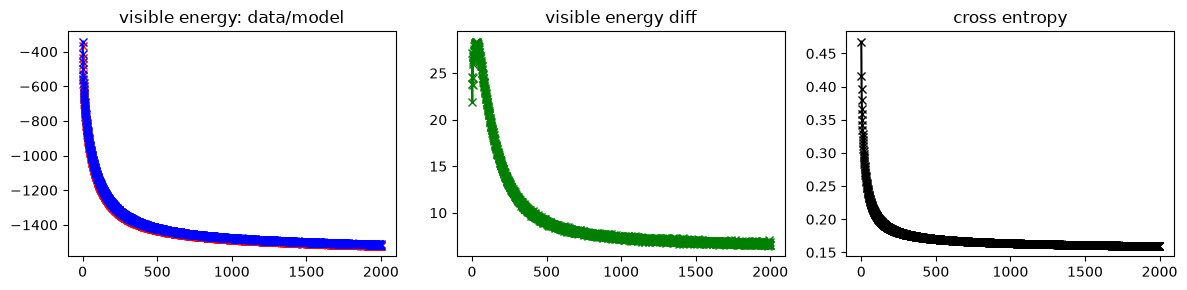

In [22]:
# Plot history

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 3))

axes[0].plot(history["E_data"],'rx-')
axes[0].plot(history["E_model"],'bx-')

axes[1].plot(history["E_diff"],'gx-')
axes[2].plot(history["CE"],'kx-')

axes[0].set_title('visible energy: data/model')
axes[1].set_title('visible energy diff')
axes[2].set_title('cross entropy')

plt.tight_layout()
plt.show()

In [23]:
# Generate starting from a random pixel distribution or a random hidden unit distribution.
# Commented out lines are for different initializations.
n_sample = 20000

ph = 0.5  # Bernoulli probability
h0 = torch.bernoulli(torch.ones(n_sample, n_hidden)*ph).float().to(device)  # bernoulli 0,1 with probability ph
X0 = rbm.h_to_v(h0)

# X0 = torch.randint(1, (n_sample, n_visible),requires_grad=False).float().to(device)  # binary 0,1
# X0 = torch.rand((n_sample, n_visible),requires_grad=False).float().to(device)  # uniform [0,1]

In [24]:
# Use Gibbs sampling for generation
with torch.no_grad():  # no graph, avoid GPU memory growth
    X_gen = rbm.forward(X0, mc='gibbs', k=1000, epsilon=0.01).detach()  # gibbs or manual diff langevin does not need graph
# X_gen is in one-hot encoding

In [25]:
# Convert categorical integers to grayscale float image
# by mapping each category to the center of its bin.

def categories_to_image(x_cat, bins=10, image_size=(32, 32)):
    """
    x_cat: [1024] or [batch, 1024] integer categories (0..bins-1)
    Returns grayscale image(s) in [0,1], shape [1, H, W] or [B, 1, H, W]
    """
    x_float = (x_cat.float() + 0.5) / bins  # map bins -> midpoints in [0,1]
    x_float = x_float.view(-1, 1, *image_size)  # add channel dim
    return x_float

In [26]:
# Convert one-hot back to categorical integers and then to images
img_gen = categories_to_image(X_gen.view(-1,n_visible,C).argmax(dim=-1),bins=C, image_size=(L, L))
print(img_gen.shape)

torch.Size([20000, 1, 32, 32])


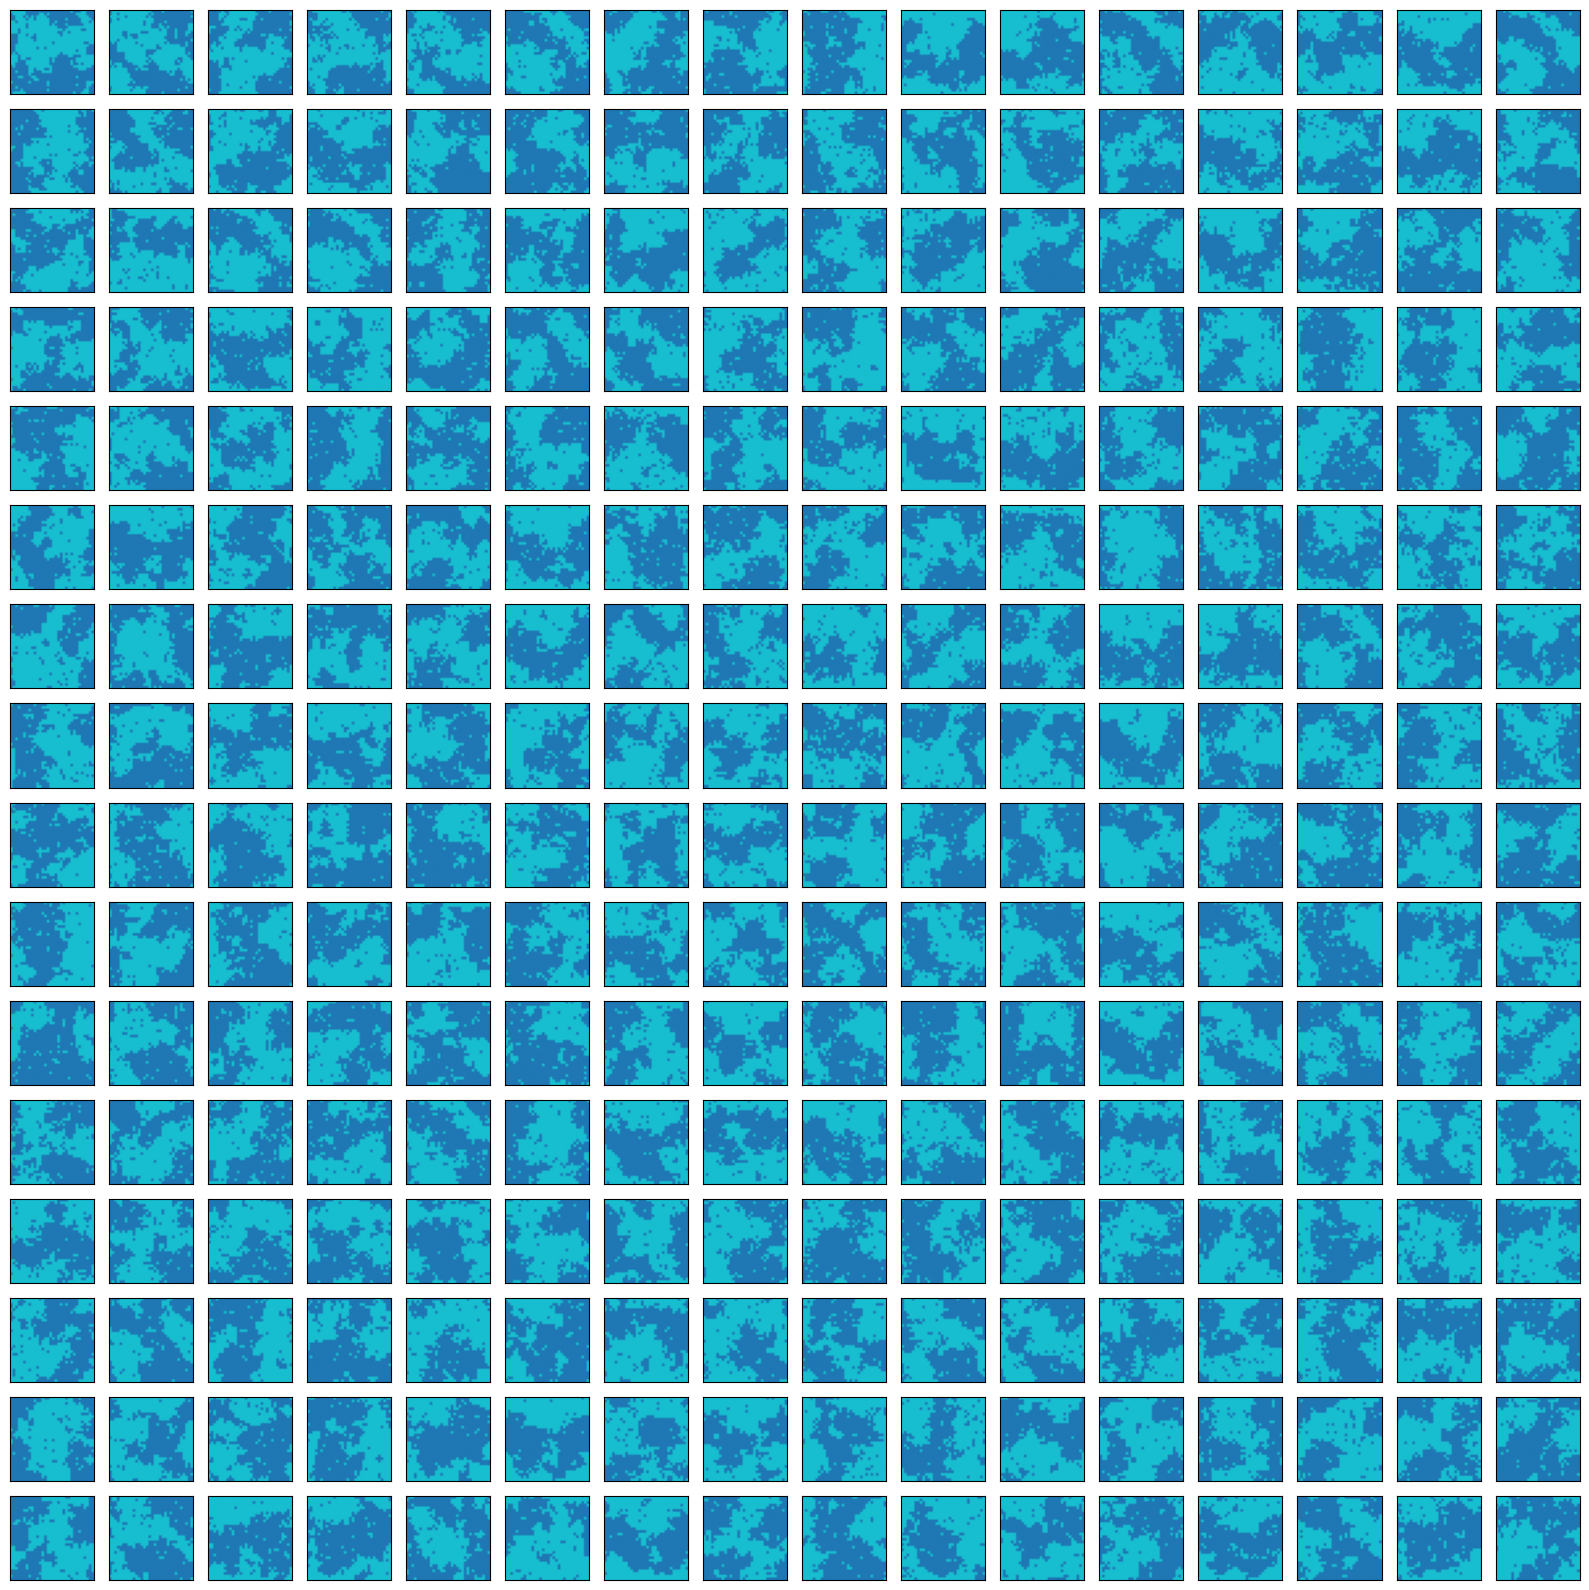

In [27]:
# See generated images

fig = plt.figure(figsize=(16, 16)) 
for i in range(256):  # 16 × 16 grid
    ax = fig.add_subplot(16, 16, i + 1)
    ax.imshow(img_gen[i].cpu().view(L, L), cmap=cmap)
    # ax.axis('off')
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

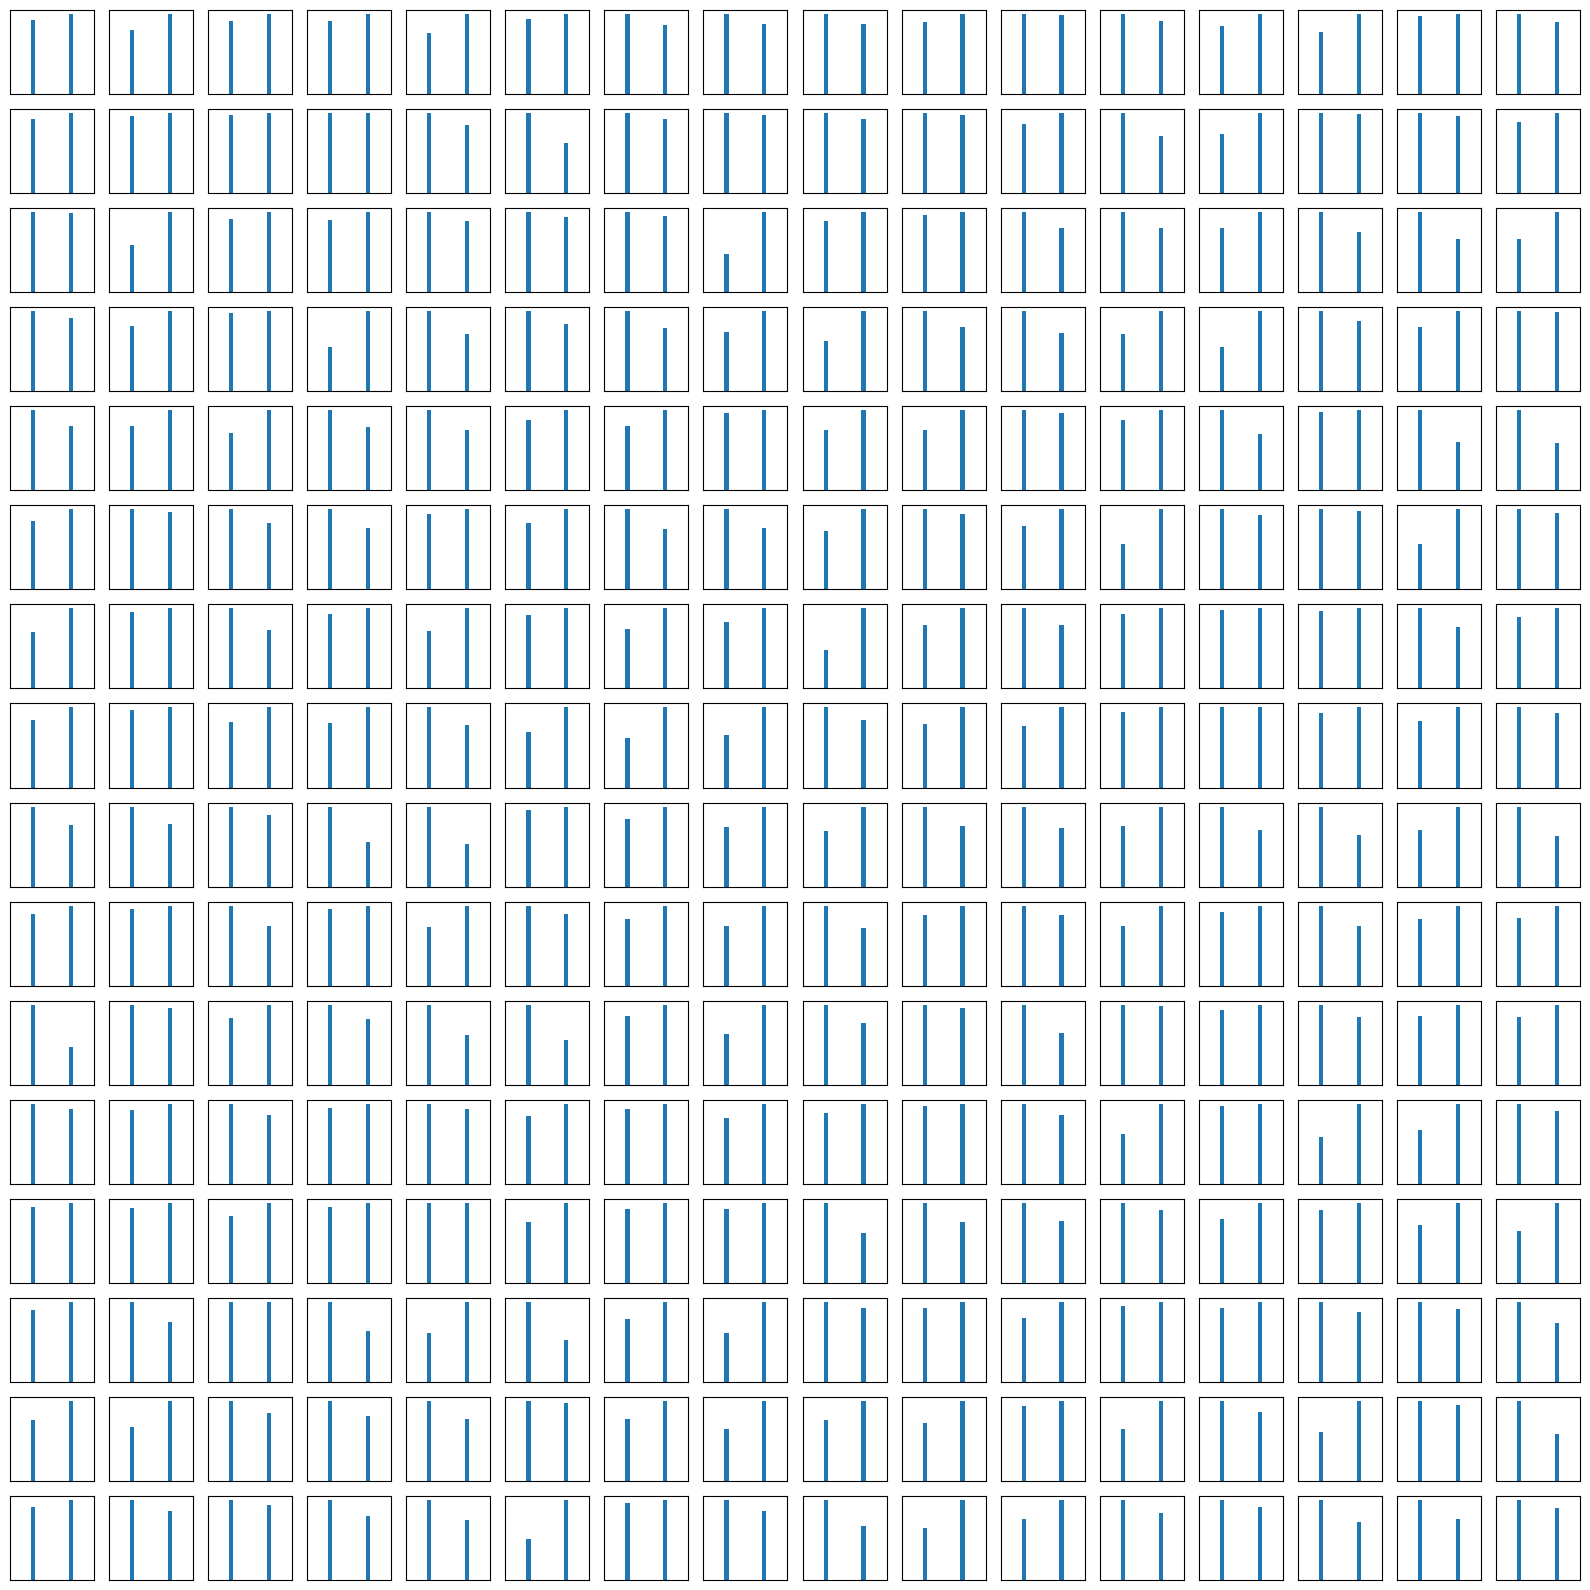

In [31]:
# Check histogram distribution

fig = plt.figure(figsize=(16, 16)) 
for i in range(256):  # 16 × 16 grid
    ax = fig.add_subplot(16, 16, i + 1)
    ax.hist(img_gen[i].cpu().view(-1)) 
    # ax.axis('off')
    ax.set_xlim(0,1)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

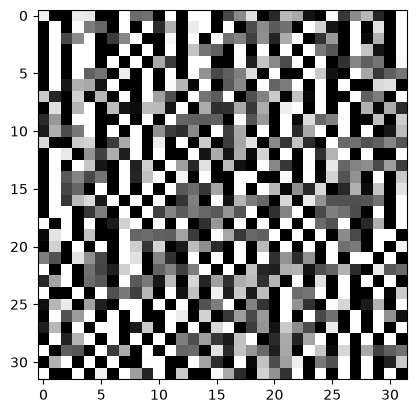

In [48]:
plt.imshow(rbm.W[25,:1024].detach().cpu().view(L, L), cmap="grey",vmin=-0.1, vmax=0.1)


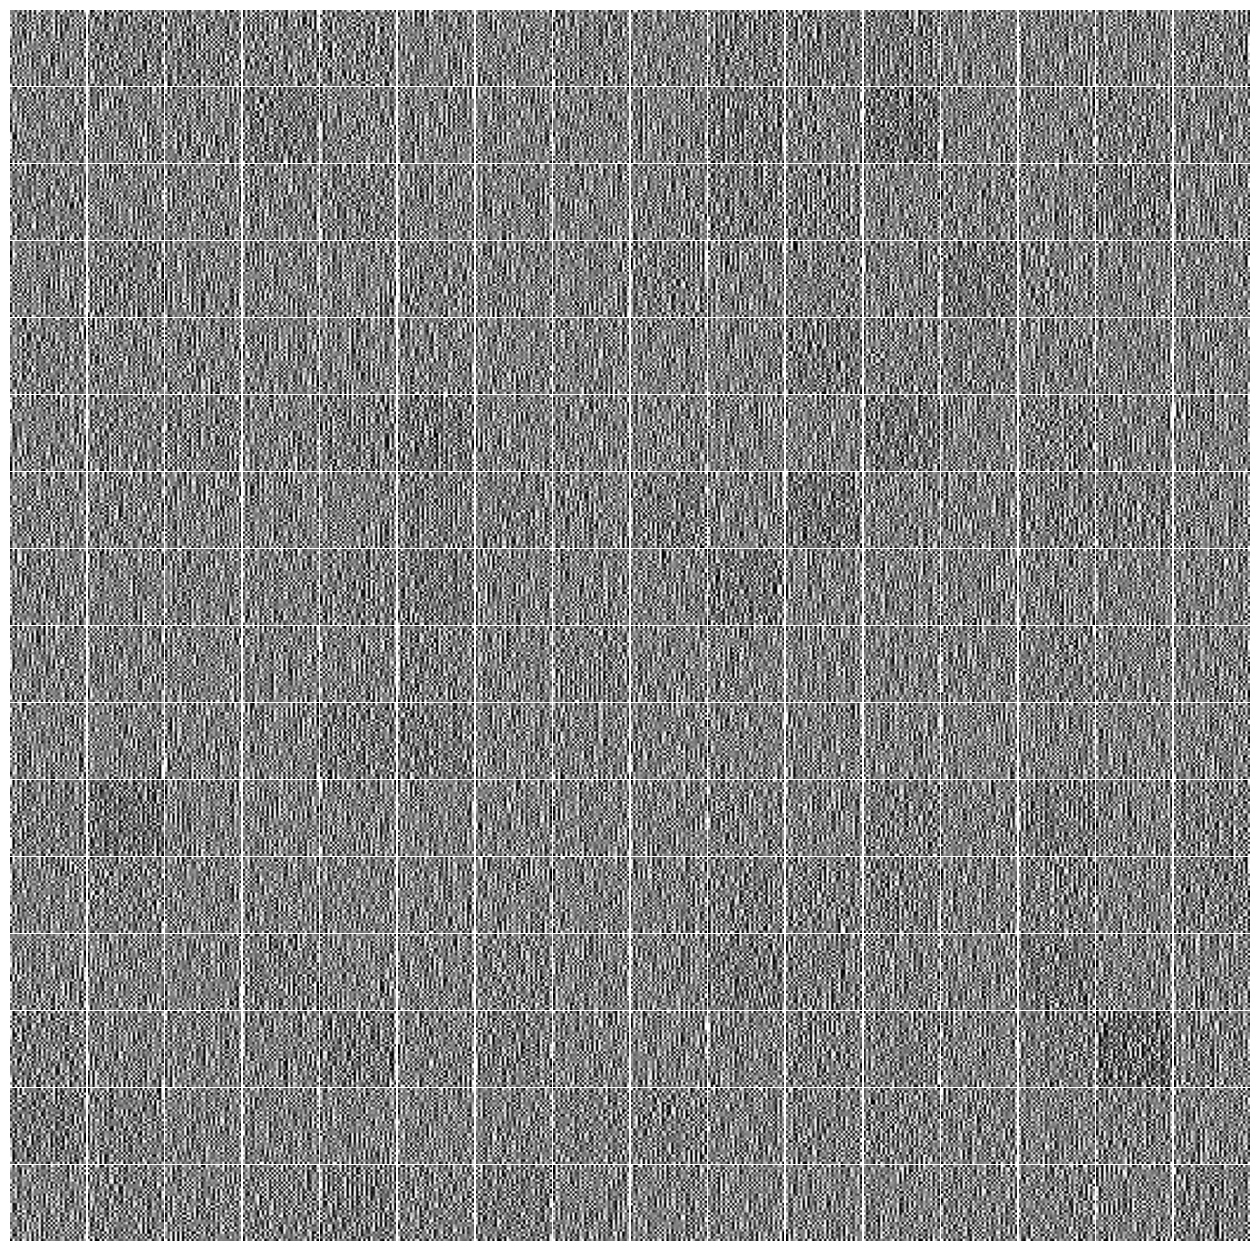

In [40]:
c = 1  # 0,1,...,C-1
fig = plt.figure(figsize=(16, 16)) 
for i in range(256):  # 16 × 16 grid
    ax = fig.add_subplot(16, 16, i + 1)
    ax.imshow(rbm.W[i,c*n_visible:(c+1)*n_visible].detach().cpu().view(L, L), cmap="gray",vmin=-0.2, vmax=0.2)
    ax.axis('off')

plt.subplots_adjust(wspace=0.02, hspace=0)
plt.margins(0., 0.)
# cbar = fig.colorbar(im, orientation='horizontal')  #, fraction=0.05, pad=0.02)
plt.show()

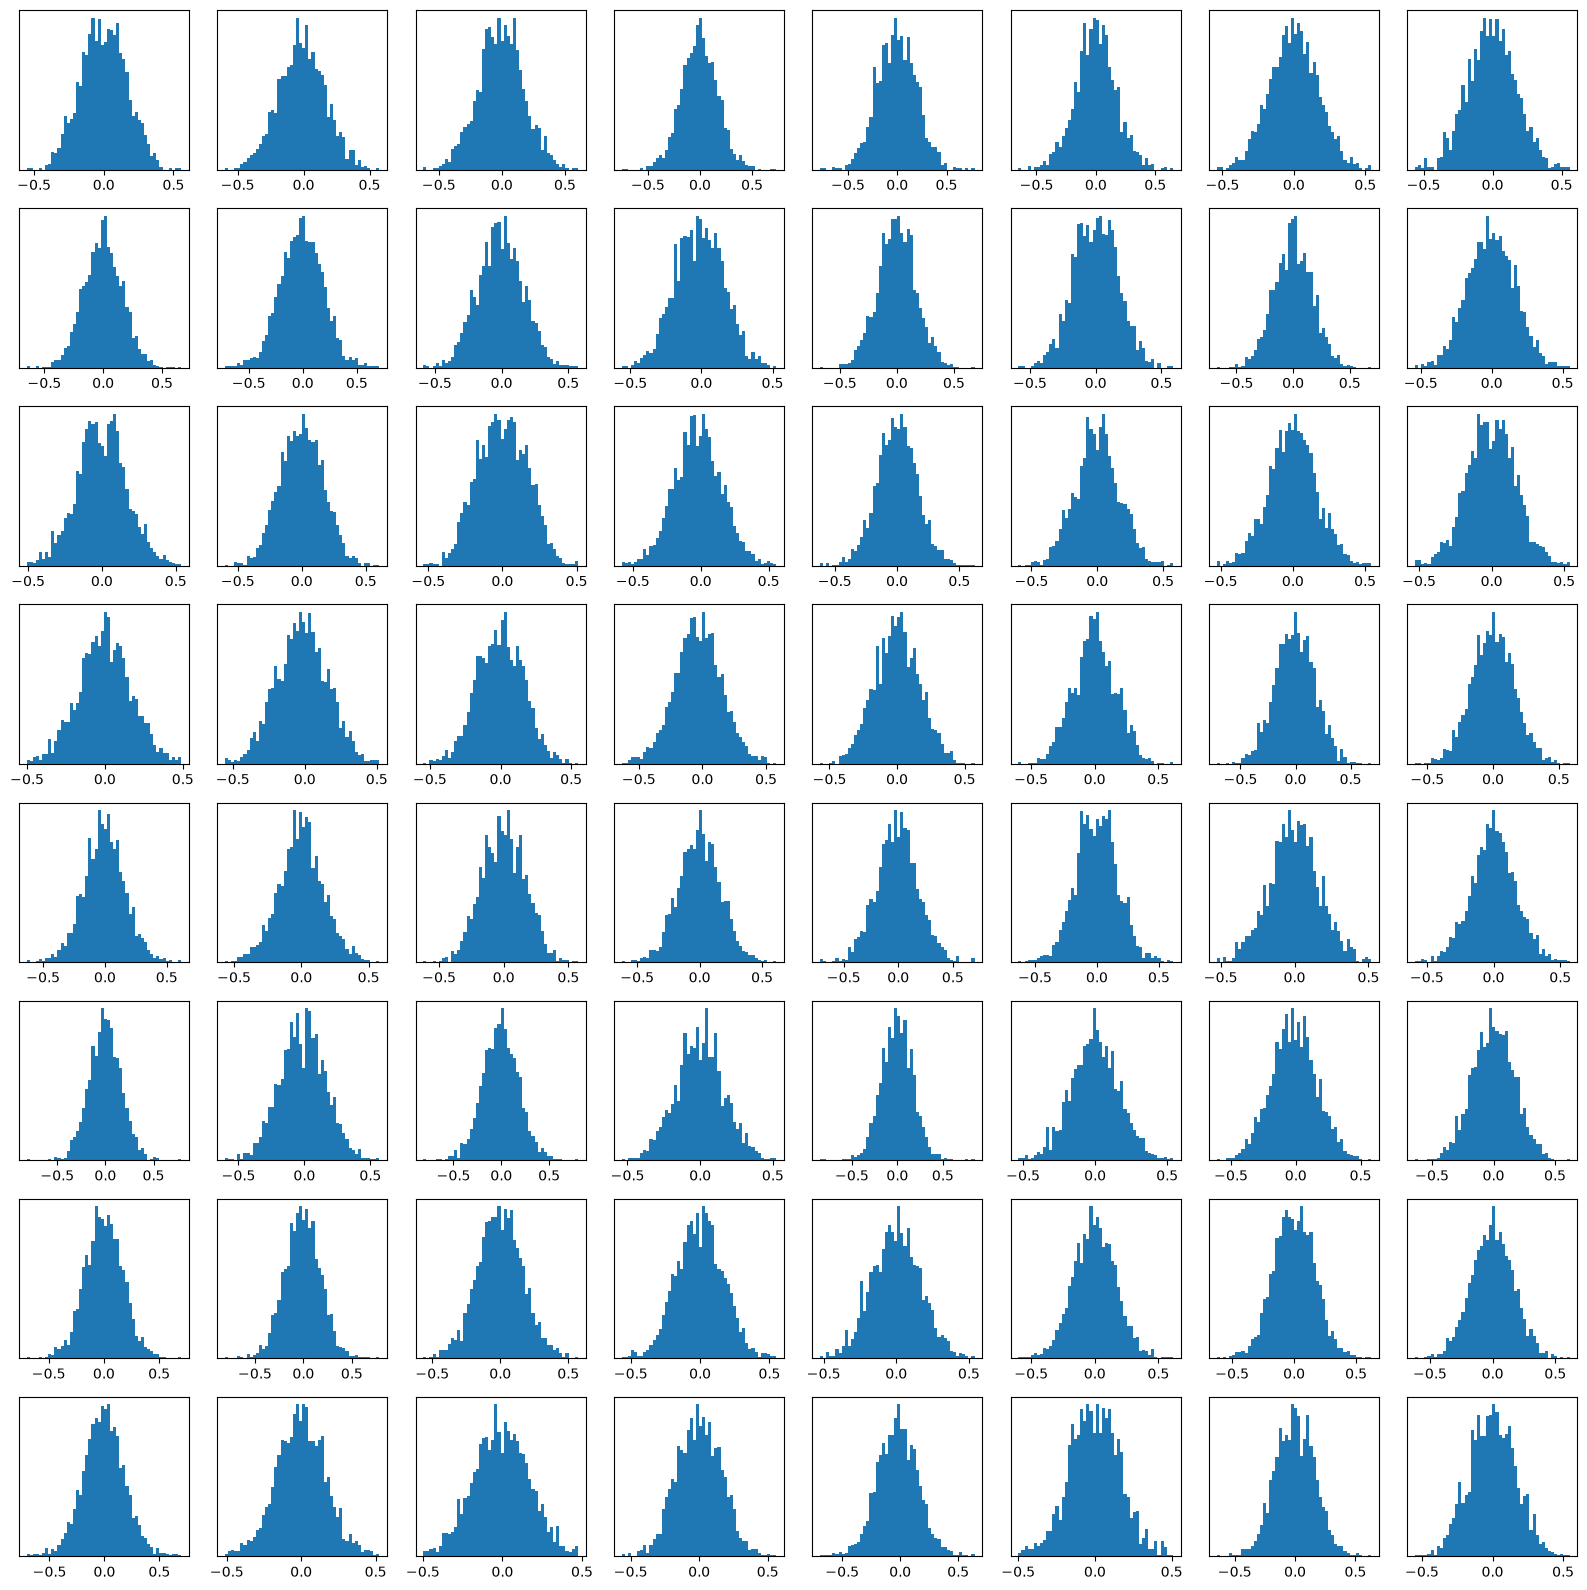

In [33]:
# Plot histogram of weight matrix W filters

fig = plt.figure(figsize=(16, 16)) 
for i in range(64):  # 16 × 16 grid
    ax = fig.add_subplot(8, 8, i + 1)
    ax.hist(rbm.W[i].detach().cpu().view(-1), bins=50)
    # ax.axis('off')
    # ax.set_xlim(-4,4)
    # ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
# cbar = fig.colorbar(im, orientation='horizontal')  #, fraction=0.05, pad=0.02)
plt.show()

In [34]:
X_cat = X_gen.view(-1,n_visible,C).argmax(dim=-1) # categorical X
configs_gen = X_cat.detach().cpu().numpy()

In [ ]:
path = './q2L32_gen/'
filename = os.path.join(path, "gen_configs_q2L32T{:.3f}.npy".format(T))
np.save(filename, configs_gen)


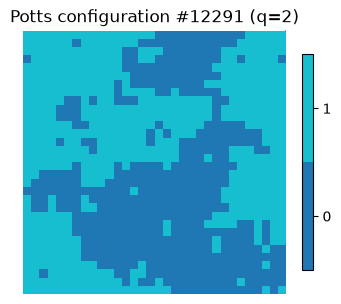

In [37]:
index = np.random.randint(configs_gen.shape[0])
config = configs_gen[index]

plt.figure(figsize=(4, 4))
plt.imshow(config.reshape(L,L), cmap="tab10", vmin=0, vmax=q-1)
#plt.imshow(config.reshape(L, L), cmap=cmap, norm=norm)

plt.title(f"Potts configuration #{index} (q={q})")
# plt.colorbar(label="Spin state")
plt.colorbar(ticks=np.arange(q),boundaries=bounds, spacing='uniform', shrink=0.7, fraction=0.1, pad=0.05)  # only integer ticks
plt.axis("off")
plt.show()